# Estimating an Issuer's CDS, OAS and Market-Implied Rating Gap (Oracle)

Oracle has borrowed heavily to build data centres for AI, and the bond market has repriced its credit. Its rating, however, moves slowly, and its CDS quotes sit behind paid terminals. This notebook shows how a credit officer can estimate the CDS curve of a name like this from public data, and measure how far the market has moved away from the agency rating.

**What it does.** It estimates the credit-default-swap curve of a single issuer without CDS quotes, Oracle Corporation, through three independent routes:

1. a **bond-implied** CDS curve from a reduced-form hazard model calibrated to the prices of Oracle's 45 bonds;
2. an **equity-implied** CDS from the CreditGrades structural model, run daily for three years;
3. a **machine-learning "fair spread"** from a LightGBM model of the spread determinants of about 4,000 U.S. corporate bonds.

It then applies the rating agencies' market-implied rating method (bond-, CDS- and equity-implied ratings) to measure Oracle's **MIR gap** against its S&P rating.

**Data.** iShares LQD and HYG holdings (bond prices, coupons, maturities), the U.S. Treasury par yield curve, Yahoo Finance equity prices, SEC EDGAR XBRL balance sheets (company facts and frames APIs), ICE BofA option-adjusted spreads by rating and maturity (FRED), and a public 5-year CDS print for validation.

**Methods.** A Treasury zero-curve bootstrap, z-spreads, piecewise-constant hazard rates by penalised least squares, ISDA-style CDS par spreads and CreditGrades.

The cross-section uses LightGBM with monotone constraints, grouped cross-validation and SHAP, against a linear determinants regression. Ratings come from a spread-band mapping with notch interpolation.

**Key output.** Oracle's estimated CDS term structure with a range across methods, its OAS and CDS–bond basis, the drivers of corporate spreads, and bond-, CDS- and equity-implied ratings with their notch gap to the agency rating over time.

## 1. Why estimate a CDS, and what the market-implied rating adds

A credit officer needs a market-based credit spread for every counterparty and issuer: to price CVA, set limits, mark loans and bonds, and challenge ratings. Most names have **no liquid CDS**, and even where CDS trade, the quotes sit behind paid terminals. The standard answer is to *estimate* the CDS from what is observable:

| Route | Observable input | Model | Strength | Weakness |
|---|---|---|---|---|
| Bond-implied | the issuer's bond prices | reduced-form hazard rates (Duffie–Singleton) | the closest market proxy | bond liquidity and funding premia leak into the spread (the CDS–bond **basis**) |
| Equity-implied | share price, equity volatility, debt | CreditGrades structural model | daily history, available for any listed firm | model risk; needs calibration of the recovery and barrier parameters |
| Cross-sectional ML | spreads and characteristics of thousands of bonds | LightGBM on spread determinants | a "fair" spread relative to peers: rich or cheap | explains the cross-section, not the timing |

**Market-implied ratings (MIR).** Agencies publish ratings that move slowly. Moody's Analytics popularised **market-implied ratings**, which map a market price (bond spread, CDS spread, or equity-based default probability) to the rating category whose typical spread it resembles. The **MIR gap** is the number of notches between the agency rating and the market-implied rating. A large negative gap (market worse than the rating) is a classic early warning of a downgrade.

**Assumptions stated up front**
- Recovery $R=40\%$ of face value at default, the market convention for senior unsecured corporate CDS and bonds.
- Discounting on the Treasury zero curve. Spreads over Treasuries are therefore OAS/z-spread-comparable with the ICE BofA indices. CDS are normally discounted on SOFR swaps; the difference is absorbed in the basis.
- **CDS–bond basis.** The baseline assumption is zero basis (CDS = bond-implied spread). The notebook measures the basis implied by a public 5-year CDS print and shows its sensitivity.
- Rating-band spreads come from the ICE BofA indices by rating (AAA … CCC) on the same day. Their maturity profile is borrowed from the investment-grade maturity-bucket indices (a multiplicative term-structure assumption).

## 2. Setup

In [1]:
# --- macOS safety switch (must run before any scientific import)
# Several libraries (PyTorch, LightGBM, scikit-learn, NumPy builds) ship their
# own OpenMP runtime.
# On Apple Silicon two copies in one process can make Jupyter report "the
# kernel crashed".
import os

os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")


# --- Standard library
import datetime as dt
import io
import re
import time
import warnings
from pathlib import Path

# --- Third-party
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.graph_objects as go
import requests
from dotenv import find_dotenv, load_dotenv
from fredapi import Fred
from plotly.subplots import make_subplots
import lightgbm as lgb
import shap
import yfinance as yf
from scipy import optimize, stats
from scipy.interpolate import PchipInterpolator
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import GroupKFold

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

PROJECT_DIR = Path.cwd()
DATA_DIR, OUT_DIR = PROJECT_DIR / "data", PROJECT_DIR / "outputs"
DATA_DIR.mkdir(exist_ok=True)
OUT_DIR.mkdir(exist_ok=True)

load_dotenv(find_dotenv(usecwd=True))
FRED_API_KEY = os.getenv("FRED_API_KEY", "").strip()
if not FRED_API_KEY:
    raise RuntimeError(
        "FRED_API_KEY not found. Create the .env file at the repo root (see"
        " .env.example)."
    )
fred = Fred(api_key=FRED_API_KEY)
BROWSER_HEADERS = {
    "User-Agent": (
        "Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7) Chrome/130.0"
        " Safari/537.36"
    )
}

SEED = 11
ISSUER, ISSUER_TICKER = "ORACLE CORPORATION", "ORCL"
# investment-grade and high-yield corporate bond ETFs
ISHARES_FUNDS = {"LQD": "239566", "HYG": "239565"}
RECOVERY = 0.40
# hazard-rate term-structure knots (years)
KNOTS = [1, 3, 5, 7, 10, 15, 20, 30, 45]
CDS_TENORS = [1, 2, 3, 5, 7, 10]
# Agency rating used for the MIR gap: S&P long-term issuer rating BBB-
# (stable), lowered from BBB on 9 July 2026
AGENCY_RATING = "BBB-"
# Public market print used only for validation: Oracle 5-year CDS at 215 bp on
# 27 July 2026 (Börse Express, 28-Jul-2026)
CDS_PRINT = (pd.Timestamp("2026-07-27"), 215.0)
SEC_USER_AGENT = os.getenv("SEC_USER_AGENT", "").strip()
if not SEC_USER_AGENT:
    raise RuntimeError(
        "SEC_USER_AGENT not found in .env (SEC requires 'Name email@domain' in"
        " the User-Agent)."
    )
SEC_HEADERS = {"User-Agent": SEC_USER_AGENT}

print(
    f"lightgbm {lgb.__version__} · shap {shap.__version__} · yfinance"
    f" {yf.__version__} · run on {dt.date.today():%Y-%m-%d}"
)

lightgbm 4.7.0 · shap 0.54.1 · yfinance 1.7.0 · run on 2026-10-20


In [2]:
# --- Caching helper: every download is stored in data/ and reused for 12 hours
def cached(name, fetch, max_age_hours=12):
    path = DATA_DIR / f"{name}.parquet"
    if (
        path.exists()
        and (time.time() - path.stat().st_mtime) / 3600 < max_age_hours
    ):
        return pd.read_parquet(path)
    try:
        frame = fetch()
        frame.to_parquet(path)
        return frame
    except Exception as err:
        if path.exists():
            print(
                f"⚠️  {name}: download failed ({type(err).__name__}); using"
                " cached copy"
            )
            return pd.read_parquet(path)
        raise


# --- Chart style
PALETTE = [
    "#2a78d6",
    "#eb6834",
    "#1baf7a",
    "#eda100",
    "#e87ba4",
    "#008300",
    "#6250d6",
    "#e34948",
]
INK, INK_2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
STATUS = {"green": "#1baf7a", "amber": "#eda100", "red": "#e34948"}
plt.rcParams.update({
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID,
    "axes.labelcolor": INK_2,
    "axes.titlecolor": INK,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.grid": True,
    "grid.color": GRID,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "xtick.color": INK_2,
    "ytick.color": INK_2,
    "legend.frameon": False,
    "lines.linewidth": 2.0,
    "font.size": 10,
    "figure.dpi": 110,
    "axes.axisbelow": True,
})


def save_fig(fig, name):
    fig.savefig(OUT_DIR / f"{name}.png", dpi=150, bbox_inches="tight")


def save_dashboard(dash, name):
    """
    Interactive HTML always; static PNG (for GitHub) when kaleido can find
    Chrome.
    """
    dash.write_html(OUT_DIR / f"{name}.html", include_plotlyjs="cdn")
    try:
        dash.write_image(OUT_DIR / f"{name}.png", scale=2)
        print(f"Dashboard saved: outputs/{name}.html and .png")
    except Exception as err:
        print(
            f"Dashboard saved as HTML; PNG skipped ({type(err).__name__}). Run"
            " `plotly_get_chrome` once."
        )


def tenor_label(t):
    return f"{int(round(t * 12))}M" if t < 1 else f"{t:g}Y"

## 3. Bonds and the Treasury zero curve

The iShares holdings files give, for every bond in the two largest U.S. corporate bond ETFs, the clean price, coupon and maturity (about 4,500 bonds of ~1,100 issuers). The Treasury par curve of the holdings date is bootstrapped into continuously compounded zero rates: par yields are interpolated with a monotone (PCHIP) spline on a semi-annual grid and discount factors are solved recursively.

For each fixed-rate bond: semi-annual coupons are dated backwards from maturity, accrued interest is added to the clean price, and the **z-spread** $s$ solves $P_\text{dirty}=\sum_i CF_i\,e^{-(z(t_i)+s)t_i}$.

In [3]:
def fetch_holdings(ticker):
    url = f"https://www.ishares.com/us/products/{ISHARES_FUNDS[ticker]}/fund/latest-holdings.csv"
    lines = requests.get(
        url, headers=BROWSER_HEADERS, timeout=60
    ).text.splitlines()
    as_of = next(
        (
            l.split(",", 1)[1].strip('" ')
            for l in lines[:10]
            if "as of" in l.lower()
        ),
        "",
    )
    header = next(
        i for i, l in enumerate(lines) if l.startswith(("Ticker", "Name"))
    )
    t = pd.read_csv(
        io.StringIO("\n".join(lines[header:])), dtype=str, on_bad_lines="skip"
    )
    t["fund"], t["as_of"] = ticker, as_of
    return t


num = lambda s: pd.to_numeric(
    s.astype(str).str.replace(",", "", regex=False), errors="coerce"
)
raw = pd.concat(
    [
        cached(f"ishares_{t}", lambda t=t: fetch_holdings(t))
        for t in ISHARES_FUNDS
    ],
    ignore_index=True,
)
raw = raw[raw["Asset Class"] == "Fixed Income"]
bonds = pd.DataFrame({
    "issuer": (
        raw["Name"]
        .str.replace(r"\s+(144A|MTN|NC[\d.]+)$", "", regex=True)
        .str.strip()
    ),
    "fund": raw["fund"],
    "sector": raw["Sector"],
    "isin": raw["ISIN"],
    "price": num(raw["Price"]),
    "coupon": num(raw["Coupon (%)"]),
    "ytm": num(raw["YTM (%)"]),
    "duration": num(raw["Mod. Duration"]),
    "par_held": num(raw["Par Value"]),
    "maturity": pd.to_datetime(
        raw["Maturity"], format="%b %d, %Y", errors="coerce"
    ),
}).reset_index(drop=True)
AS_OF = pd.to_datetime(raw["as_of"].iloc[0], format="%b %d, %Y")
bonds["T"] = (bonds["maturity"] - AS_OF).dt.days / 365.25
bonds = (
    bonds[(bonds["T"] > 0.25) & (bonds["price"] > 5) & bonds["coupon"].notna()]
    .drop_duplicates("isin")
    .reset_index(drop=True)
)

TREASURY_URL = (
    "https://home.treasury.gov/resource-center/data-chart-center/interest-rates/daily-treasury-rates.csv/"
    "{y}/all?type=daily_treasury_yield_curve&field_tdr_date_value={y}&page&_format=csv"
)


def fetch_par():
    t = pd.read_csv(
        io.StringIO(
            requests.get(
                TREASURY_URL.format(y=AS_OF.year),
                headers=BROWSER_HEADERS,
                timeout=60,
            ).text
        )
    )
    t["date"] = pd.to_datetime(t["Date"], format="%m/%d/%Y")
    return t


par = cached("treasury_par", fetch_par).set_index("date").sort_index()
par = par.loc[:AS_OF].iloc[-1]
ten = {
    c: float(c.split()[0]) / (12 if "Mo" in c else 1)
    for c in par.index
    if re.match(r"^[\d.]+ (Mo|Yr)$", c)
}
pc = pd.Series({ten[c]: par[c] for c in ten}).dropna().sort_index() / 100
pc = pc[~pc.index.isin([1.5 / 12, 4 / 12])] if len(pc) > 12 else pc
grid = np.arange(0.5, 30.01, 0.5)
par_g = PchipInterpolator(pc.index, pc.values)(grid)
dfs = []
for n, c in enumerate(par_g, 1):
    dfs.append((1 - c / 2 * sum(dfs)) / (1 + c / 2))
zero_t = np.concatenate([[1 / 12], grid])
zero_r = np.concatenate(
    [[np.log(1 + pc.iloc[0] / 12) * 12], -np.log(np.array(dfs)) / grid]
)


def zero(t):
    t = np.asarray(t, float)
    return np.interp(t, zero_t, zero_r, left=zero_r[0], right=zero_r[-1])


def DF(t):
    return np.exp(-zero(t) * np.asarray(t, float))


def schedule(maturity, coupon):
    """
    Cash-flow times (years from AS_OF) and amounts per 100 face, plus accrued
    interest.
    """
    dates = [maturity]
    while dates[-1] > AS_OF:
        dates.append(dates[-1] - pd.DateOffset(months=6))
    prev, cfd = dates[-1], sorted(dates[:-1])
    acc = coupon / 2 * (AS_OF - prev).days / (cfd[0] - prev).days
    t = np.array([(d - AS_OF).days / 365.25 for d in cfd])
    cf = np.full(len(t), coupon / 2)
    cf[-1] += 100
    return t, cf, acc


def zspread(row):
    t, cf, acc = schedule(row["maturity"], row["coupon"])
    dirty = row["price"] + acc
    f = lambda s: np.sum(cf * np.exp(-(zero(t) + s) * t)) - dirty
    try:
        return optimize.brentq(f, -0.05, 0.6)
    except ValueError:
        return np.nan


bonds["z_bp"] = [zspread(r) * 1e4 for _, r in bonds.iterrows()]
bonds = bonds[bonds["z_bp"].between(-50, 3000)].reset_index(drop=True)
print(
    f"Holdings as of {AS_OF:%Y-%m-%d}: {len(bonds):,} bonds,"
    f" {bonds['issuer'].nunique():,} issuers (LQD"
    f" {(bonds['fund'] == 'LQD').sum():,}, HYG"
    f" {(bonds['fund'] == 'HYG').sum():,}) · Treasury 2y {zero(2) * 100:.2f}%,"
    f" 10y {zero(10) * 100:.2f}%, 30y {zero(30) * 100:.2f}% (zero, cont.)"
)
print(
    "Median z-spread: LQD"
    f" {bonds.loc[bonds.fund == 'LQD', 'z_bp'].median():.0f} bp, HYG"
    f" {bonds.loc[bonds.fund == 'HYG', 'z_bp'].median():.0f} bp"
)
orcl = bonds[bonds["issuer"] == ISSUER].sort_values("T").reset_index(drop=True)
orcl[["isin", "coupon", "maturity", "price", "ytm", "duration", "z_bp"]].head(
    8
).round({"price": 2, "z_bp": 1})

Holdings as of 2026-10-19: 4,484 bonds, 1,068 issuers (LQD 3,181, HYG 1,303) · Treasury 2y 4.72%, 10y 5.12%, 30y 5.46% (zero, cont.)
Median z-spread: LQD 80 bp, HYG 205 bp


,isin,coupon,maturity,price,ytm,duration,z_bp
0,US68389XCH61,6.15,2029-11-09,97.87,6.93,2.66,202.20
1,US68389XBV64,2.95,2030-04-01,87.33,7.16,3.17,221.60
2,US68389XCN30,4.65,2030-05-06,92.56,7.05,3.12,212.10
3,US68389XDH52,4.45,2030-09-26,90.60,7.24,3.50,227.10
4,US68389XDX03,4.95,2031-02-04,90.90,7.46,3.72,247.40
5,US68389XCE31,2.88,2031-03-25,83.30,7.36,4.01,237.60
6,US68389XCZ69,5.25,2032-02-03,90.29,7.50,4.43,247.30
7,US68389XDK81,4.80,2032-09-26,86.46,7.68,4.96,261.10


## 4. Route 1 — bond-implied CDS curve (reduced-form hazard model)

Default is the first jump of a Poisson process with a piecewise-constant intensity $\lambda(t)$ between the knots 1, 3, 5, 7, 10, 15, 20, 30, 45 years. Survival is $Q(t)=\exp(-\int_0^t\lambda)$. A bond pays its coupons and principal if the issuer survives, and recovers $R$ of face at default (recovery of face value, the bond-market convention):

$$P^\text{model}=\sum_i CF_i\,D(t_i)\,Q(t_i)+R\cdot100\int_0^T D(u)\,(-dQ(u)).$$

The knots' log-intensities are fitted by least squares on the 45 Oracle bond prices (errors weighted by $1/\text{duration}$, so each bond counts in spread terms), plus a small penalty on changes in $\log\lambda$ between knots for stability. The CDS par spread then follows ISDA mechanics: quarterly premiums, accrual on default, protection $(1-R)$:

$$s(T)=\frac{(1-R)\int_0^T D\,(-dQ)}{\sum_j \Delta_j D(t_j)Q(t_j)+\tfrac12\int_0^T \Delta(u)D(u)(-dQ(u))}.$$

In [4]:
# monthly grid for the default integrals
FINE = np.arange(1 / 12, 50.01, 1 / 12)


def survival(loglam, t):
    lam = np.exp(loglam)
    edges = np.concatenate([[0.0], KNOTS[:-1]])
    lam_t = lam[np.searchsorted(edges, np.asarray(t), side="right") - 1]
    grid_l = lam[np.searchsorted(edges, FINE, side="right") - 1]
    H = np.concatenate([[0.0], np.cumsum(grid_l / 12)])
    return np.exp(
        -np.interp(np.asarray(t, float), np.concatenate([[0.0], FINE]), H)
    )


def bond_model_price(loglam, t, cf):
    Q = survival(loglam, t)
    g = FINE[FINE <= t[-1] + 1e-9]
    Qg = survival(loglam, np.concatenate([[0.0], g]))
    rec = RECOVERY * 100 * np.sum(DF(g) * -np.diff(Qg))
    return np.sum(cf * DF(t) * Q) + rec


sched = [schedule(m, c) for m, c in zip(orcl["maturity"], orcl["coupon"])]
dirty = orcl["price"].to_numpy() + np.array([s[2] for s in sched])
w = 1 / np.clip(orcl["duration"].to_numpy(), 0.5, None)


def resid(x, pen=2.0):
    err = np.array([bond_model_price(x, t, cf) for t, cf, _ in sched]) - dirty
    return np.concatenate([err * w, pen * np.diff(x)])


fit = optimize.least_squares(
    resid, np.log(np.full(len(KNOTS), 0.02)), method="trf"
)
LOGLAM = fit.x
orcl["model_price"] = [
    bond_model_price(LOGLAM, t, cf) - a for t, cf, a in sched
]
orcl["price_err"] = orcl["model_price"] - orcl["price"]
orcl["err_bp"] = (
    -orcl["price_err"] / np.clip(orcl["duration"], 0.3, None) * 100
)


def cds_par(loglam, T):
    g = FINE[FINE <= T + 1e-9]
    Q = survival(loglam, np.concatenate([[0.0], g]))
    dQ = -np.diff(Q)
    prot = (1 - RECOVERY) * np.sum(DF(g) * dQ)
    qt = np.arange(0.25, T + 1e-9, 0.25)
    rpv01 = np.sum(0.25 * DF(qt) * survival(loglam, qt)) + 0.5 * np.sum(
        (1 / 12) * DF(g) * dQ
    )
    return prot / rpv01 * 1e4


bond_cds = pd.Series(
    {T: cds_par(LOGLAM, T) for T in CDS_TENORS}, name="bond-implied CDS (bp)"
)
haz = pd.DataFrame({
    "from (y)": [0] + KNOTS[:-1],
    "to (y)": KNOTS,
    "hazard %/yr": np.exp(LOGLAM) * 100,
})
print(
    f"Fit on {len(orcl)} Oracle bonds: RMSE"
    f" {np.sqrt((orcl['price_err'] ** 2).mean()):.2f} points of price,"
    f" {np.sqrt((orcl['err_bp'] ** 2).mean()):.0f} bp in spread terms; 5y"
    f" survival {survival(LOGLAM, 5.0):.2%}"
)
display(haz.round(3).set_index(["from (y)", "to (y)"]).T)
bond_cds.round(0).to_frame().T

Fit on 45 Oracle bonds: RMSE 1.69 points of price, 16 bp in spread terms; 5y survival 80.94%


from (y),0,1,3,5,7,10,15,20,30
to (y),1,3,5,7,10,15,20,30,45
hazard %/yr,3.60,3.87,4.86,6.11,7.52,9.36,10.86,11.65,11.76


,1,2,3,5,7,10
bond-implied CDS (bp),219.00,226.00,230.00,252.00,278.00,313.00


## 5. Route 2 — equity-implied CDS (CreditGrades), daily for three years

CreditGrades (Finger et al., 2002, RiskMetrics) models the firm's asset value as a lognormal process and default as the first passage below a barrier $\bar L D$, where $D$ is debt per share and the recovery level $\bar L$ is itself uncertain (log-normal with dispersion $\lambda$).

That uncertainty is what produces non-zero short-term spreads. With $S$ the share price and $\sigma_S$ the equity volatility, the asset volatility is $\sigma=\sigma_S S/(S+\bar L D)$. With $d=\frac{S_0+\bar LD}{\bar LD}e^{\lambda^2}$ and $A_t^2=\sigma^2t+\lambda^2$, survival is

$$P(t)=\Phi\!\left(-\tfrac{A_t}{2}+\tfrac{\ln d}{A_t}\right)-d\,\Phi\!\left(-\tfrac{A_t}{2}-\tfrac{\ln d}{A_t}\right),$$

and the CDS spread has a closed form (Finger et al., eq. 2.13). Inputs:
- daily Oracle share price and equity volatility, measured by EWMA with λ = 0.98 on returns winsorised at ±15% (see the code comment for why);
- financial debt per share from Oracle's SEC filings (long-term debt including the current portion, plus commercial paper and notes payable), applied 45 days after each quarter end, when the 10-Q is public.

**Calibration.** The textbook parameters are $\bar L=0.5$ and $\lambda=0.3$. The notebook also calibrates $\bar L$ so that the model matches the single public CDS print (215 bp on 27 July 2026), and then runs the calibrated model through time. This "anchor once, then let equity drive" approach is how structural models are used for names without CDS.

In [5]:
def fetch_equity():
    px = yf.download(
        [ISSUER_TICKER], period="4y", auto_adjust=True, progress=False
    )["Close"]
    px.index = pd.to_datetime(px.index).tz_localize(None)
    return (
        px.rename(columns={ISSUER_TICKER: "close"})
        .reset_index()
        .rename(columns={"Date": "date"})
    )


def sec_json(url):
    r = requests.get(url, headers=SEC_HEADERS, timeout=60)
    r.raise_for_status()
    time.sleep(0.12)
    return r.json()


# XBRL tags differ by filer: take the first available tag for the non-current
# and the current part of financial debt
DEBT_NONCURRENT = [
    "LongTermDebtNoncurrent",
    "LongTermNotesAndLoans",
    "LongTermNotesPayable",
    "LongTermDebt",
]
DEBT_CURRENT = ["LongTermDebtCurrent", "NotesPayableCurrent", "DebtCurrent"]


def fetch_debt_history():
    cik = {
        r["ticker"]: r["cik_str"]
        for r in sec_json(
            "https://www.sec.gov/files/company_tickers.json"
        ).values()
    }[ISSUER_TICKER]
    facts = sec_json(
        f"https://data.sec.gov/api/xbrl/companyfacts/CIK{cik:010d}.json"
    )["facts"]
    rows = []
    for tag in (
        DEBT_NONCURRENT
        + DEBT_CURRENT
        + [
            "CommercialPaper",
            "ShortTermBorrowings",
            "DebtLongtermAndShorttermCombinedAmount",
            "CommonStockSharesOutstanding",
        ]
    ):
        for unit, obs in (
            facts.get("us-gaap", {}).get(tag, {}).get("units", {}).items()
        ):
            for o in obs:
                if (
                    o.get("form", "").startswith(("10-K", "10-Q"))
                    and "end" in o
                ):
                    rows.append({
                        "tag": tag,
                        "end": o["end"],
                        "val": o["val"],
                        "filed": o["filed"],
                    })
    for o in (
        facts.get("dei", {})
        .get("EntityCommonStockSharesOutstanding", {})
        .get("units", {})
        .get("shares", [])
    ):
        rows.append({
            "tag": "SharesCover",
            "end": o["end"],
            "val": o["val"],
            "filed": o["filed"],
        })
    return pd.DataFrame(rows)


eq = (
    cached("orcl_equity", fetch_equity, max_age_hours=24)
    .set_index("date")["close"]
    .dropna()
)
dh = cached("orcl_sec_debt", fetch_debt_history, max_age_hours=24 * 7)
dh["end"] = pd.to_datetime(dh["end"])
q = (
    dh.sort_values("filed")
    .groupby(["tag", "end"])["val"]
    .last()
    .unstack(0)
    .sort_index()
)
first = lambda tags: (
    q[[t for t in tags if t in q]].bfill(axis=1).iloc[:, 0]
    if any(t in q for t in tags)
    else pd.Series(np.nan, q.index)
)
noncur, cur = first(DEBT_NONCURRENT), first(DEBT_CURRENT).fillna(0)
cp = (
    sum(
        q[c].fillna(0)
        for c in ["CommercialPaper", "ShortTermBorrowings"]
        if c in q
    )
    if any(c in q for c in ["CommercialPaper", "ShortTermBorrowings"])
    else 0
)
total = (noncur + cur + cp).where(
    noncur.notna(), q.get("DebtLongtermAndShorttermCombinedAmount")
)
shares = (
    q["CommonStockSharesOutstanding"].combine_first(q["SharesCover"])
    if "SharesCover" in q
    else q["CommonStockSharesOutstanding"]
)
debt = pd.DataFrame(
    {"debt_bn": total / 1e9, "shares_bn": shares.ffill() / 1e9}
).dropna()
debt = debt[debt["debt_bn"] > 0]
debt = debt[debt.index >= eq.index.min() - pd.Timedelta(days=400)]
avail = debt.copy()
avail.index = avail.index + pd.Timedelta(days=45)
daily = pd.DataFrame({"S": eq}).join(avail.reindex(eq.index, method="ffill"))
daily["D"] = daily["debt_bn"] / daily["shares_bn"]
# EWMA volatility (λ = 0.98, half-life ≈ 34 trading days) on returns winsorised
# at ±15%: a rolling 252-day window would make the
# spread jump when a single extreme day (Oracle's +36% on 10-Sep-2025) leaves
# the window
ret = np.log(daily["S"]).diff().clip(-0.15, 0.15)
daily["sigS"] = np.sqrt((ret**2).ewm(alpha=0.02, min_periods=126).mean() * 252)
r5 = (
    fred.get_series("DGS5", observation_start=daily.index.min()).reindex(
        daily.index, method="ffill"
    )
    / 100
)
daily["r"] = r5
daily = daily.dropna()
print(
    f"Oracle equity to {daily.index.max():%Y-%m-%d}: price"
    f" {daily['S'].iloc[-1]:.2f}, EWMA vol {daily['sigS'].iloc[-1]:.0%},"
    f" financial debt ${debt['debt_bn'].iloc[-1]:.0f}bn at"
    f" {debt.index.max():%Y-%m-%d} (${daily['D'].iloc[-1]:.2f}/share; was"
    f" ${debt['debt_bn'].iloc[0]:.0f}bn at {debt.index.min():%Y-%m-%d})"
)
debt.tail(6).round(2)

Oracle equity to 2026-10-19: price 129.59, EWMA vol 58%, financial debt $125bn at 2026-08-31 ($41.45/share; was $78bn at 2021-11-30)


,debt_bn,shares_bn
end,,
2025-05-31,92.57,2.81
2025-08-31,91.32,2.84
2025-11-30,108.08,2.87
2026-02-28,134.60,2.88
2026-05-31,129.54,2.88
2026-08-31,125.34,3.02


In [6]:
def creditgrades(S, sigS, D, r, T=5.0, Lbar=0.5, lam=0.3, R=RECOVERY):
    """CreditGrades CDS spread in bp (Finger et al. 2002, closed form)."""
    S, sigS, D, r = map(np.asarray, (S, sigS, D, r))
    sig = sigS * S / (S + Lbar * D)
    d = (S + Lbar * D) / (Lbar * D) * np.exp(lam**2)
    xi = lam**2 / sig**2
    z = np.sqrt(0.25 + 2 * r / sig**2)
    N = stats.norm.cdf

    def P(t):
        A = np.sqrt(sig**2 * t + lam**2)
        return N(-A / 2 + np.log(d) / A) - d * N(-A / 2 - np.log(d) / A)

    def G(u):
        su = sig * np.sqrt(u)
        return d ** (z + 0.5) * N(-np.log(d) / su - z * su) + d ** (
            -z + 0.5
        ) * N(-np.log(d) / su + z * su)

    H = np.exp(r * xi) * (G(T + xi) - G(xi))
    P0 = P(1e-10)
    c = r * (1 - R) * (1 - P0 + H) / (P0 - P(T) * np.exp(-r * T) - H)
    return c * 1e4


row_print = daily.loc[: CDS_PRINT[0]].iloc[-1]
cg_std = creditgrades(daily["S"], daily["sigS"], daily["D"], daily["r"])
Lbar_cal = optimize.brentq(
    lambda L: creditgrades(
        row_print["S"],
        row_print["sigS"],
        row_print["D"],
        row_print["r"],
        Lbar=L,
    )
    - CDS_PRINT[1],
    0.05,
    3.0,
)
cg_cal = creditgrades(
    daily["S"], daily["sigS"], daily["D"], daily["r"], Lbar=Lbar_cal
)
daily["cg_standard"], daily["cg_calibrated"] = cg_std, cg_cal
cg_term = pd.Series(
    {
        T: float(
            creditgrades(
                daily["S"].iloc[-1],
                daily["sigS"].iloc[-1],
                daily["D"].iloc[-1],
                daily["r"].iloc[-1],
                T=T,
                Lbar=Lbar_cal,
            )
        )
        for T in CDS_TENORS
    },
    name="equity-implied CDS (bp)",
)
print(
    f"CreditGrades 5y on {CDS_PRINT[0]:%Y-%m-%d}:"
    f" {float(creditgrades(row_print['S'], row_print['sigS'], row_print['D'], row_print['r'])):.0f} bp"
    " with the textbook L̄=0.5 vs the 215 bp print → calibrated L̄ ="
    f" {Lbar_cal:.2f}"
)
print(
    f"Latest ({daily.index.max():%Y-%m-%d}): standard"
    f" {daily['cg_standard'].iloc[-1]:.0f} bp, calibrated"
    f" {daily['cg_calibrated'].iloc[-1]:.0f} bp; 3 years ago"
    f" {daily['cg_calibrated'].iloc[0]:.0f} bp"
)

CreditGrades 5y on 2026-07-27: 319 bp with the textbook L̄=0.5 vs the 215 bp print → calibrated L̄ = 0.30
Latest (2026-10-19): standard 219 bp, calibrated 134 bp; 3 years ago 0 bp


## 6. Route 3 — spread determinants and an ML "fair spread"

The determinants of credit spreads are well established (Collin-Dufresne, Goldstein & Martin, 2001; Campbell & Taksler, 2003): **leverage, equity volatility, firm size, recent equity performance, maturity and the coupon**, plus rating (here proxied by index membership: LQD investment grade, HYG high yield) and sector. Bond issuers are matched to their listed parent's ticker by normalised name (SEC ticker file).

Leverage uses the SEC XBRL **frames** API, which returns one balance-sheet item for every filer in a single call (latest calendar-quarter instant available). Price and yield are excluded from the features, because they are the target in disguise.

- **Target:** $\log$ z-spread, bond by bond.
- **Models:** a linear determinants regression vs LightGBM with monotone constraints (spread increases with leverage, volatility and the CreditGrades spread; decreases with size and past returns). The CreditGrades spread of each issuer enters as one more feature: a *hybrid* structural-ML model.
- **Validation:** 5-fold **grouped** cross-validation by issuer, so a model is never scored on an issuer it has seen. The Oracle bonds are always held out.

In [7]:
NORM_DROP = r"\b(INC|CORP|CORPORATION|CO|COMPANY|LLC|LP|PLC|LTD|LIMITED|THE|NV|SA|AG|SE|MTN|144A|DE|HOLDINGS?)\b"


def norm(s):
    s = re.sub(r"[^A-Z0-9& ]", " ", s.upper().replace("/THE", "")).replace(
        "&", " AND "
    )
    return re.sub(r"\s+", " ", re.sub(NORM_DROP, " ", s)).strip()


def fetch_universe():
    tick = pd.DataFrame(
        sec_json("https://www.sec.gov/files/company_tickers.json")
    ).T
    tick["key"] = tick["title"].map(norm)
    tick = tick.drop_duplicates("key")
    frames = {}
    for tag, unit in [
        ("Liabilities", "USD"),
        ("LongTermDebt", "USD"),
        ("LongTermDebtNoncurrent", "USD"),
        ("LongTermNotesAndLoans", "USD"),
        ("LongTermNotesPayable", "USD"),
        ("StockholdersEquity", "USD"),
        ("Assets", "USD"),
    ]:
        for per in [
            f"CY{AS_OF.year}Q3I",
            f"CY{AS_OF.year}Q2I",
            f"CY{AS_OF.year}Q1I",
            f"CY{AS_OF.year - 1}Q4I",
        ]:
            try:
                d = pd.DataFrame(
                    sec_json(
                        f"https://data.sec.gov/api/xbrl/frames/us-gaap/{tag}/{unit}/{per}.json"
                    )["data"]
                )
            except requests.HTTPError:
                continue
            d = (
                d.sort_values("end")
                .drop_duplicates("cik", keep="last")
                .set_index("cik")["val"]
            )
            frames[tag] = (
                d if tag not in frames else frames[tag].combine_first(d)
            )
    fr = pd.DataFrame(frames)
    fr.index.name = "cik_str"
    return tick.merge(fr.reset_index(), on="cik_str", how="left")


uni = cached("sec_universe", fetch_universe, max_age_hours=24 * 7)
bonds["key"] = bonds["issuer"].map(norm)
DEBT_TAGS = [
    "LongTermDebt",
    "LongTermDebtNoncurrent",
    "LongTermNotesAndLoans",
    "LongTermNotesPayable",
]
m = bonds.merge(
    uni[
        ["key", "ticker", "Liabilities", "StockholdersEquity", "Assets"]
        + DEBT_TAGS
    ],
    on="key",
    how="left",
)
tickers = sorted(m["ticker"].dropna().unique())


def fetch_universe_prices():
    px = yf.download(
        tickers, period="15mo", auto_adjust=True, progress=False, threads=True
    )["Close"]
    px.index = pd.to_datetime(px.index).tz_localize(None)
    return px.reset_index().rename(columns={"Date": "date"})


upx = (
    cached("universe_prices", fetch_universe_prices, max_age_hours=24)
    .set_index("date")
    .sort_index()
)
lr = np.log(upx).diff()
eqf = pd.DataFrame({
    "vol_1y": lr.iloc[-252:].std() * np.sqrt(252),
    "ret_6m": upx.ffill().iloc[-1] / upx.ffill().iloc[-126] - 1,
    "last_px": upx.ffill().iloc[-1],
    "obs": upx.iloc[-252:].notna().sum(),
})
eqf = eqf[eqf["obs"] > 200]
m = m.merge(eqf, left_on="ticker", right_index=True, how="left")
# first available debt tag; half of liabilities as last resort
m["debt"] = (
    m[DEBT_TAGS].bfill(axis=1).iloc[:, 0].fillna(m["Liabilities"] * 0.5)
)
m["mktcap_proxy"] = np.where(
    m["StockholdersEquity"] > 0, m["StockholdersEquity"], np.nan
)
print(
    f"Issuer→ticker match: {m['ticker'].notna().mean():.0%} of bonds"
    f" ({m.loc[m.ticker.notna(), 'issuer'].nunique()} issuers); with equity"
    f" data: {m['vol_1y'].notna().mean():.0%}"
)

Issuer→ticker match: 58% of bonds (462 issuers); with equity data: 58%


In [8]:
# Market capitalisation needs shares: the frames API's share count is patchy,
# so equity value = book equity × price momentum is avoided;
# instead leverage is measured as debt / assets (book), and size as log assets.
m["lev"] = (m["debt"] / m["Assets"]).clip(0, 1.5)
m["log_assets"] = np.log(m["Assets"])
m["hy"] = (m["fund"] == "HYG").astype(int)
m["log_z"] = np.log(np.clip(m["z_bp"], 5, None))
# Issuer-level CreditGrades with book leverage (debt per unit of equity value
# proxied by debt/assets)
m["cg_feature"] = np.log(np.clip(m["vol_1y"] * (1 + m["lev"]), 0.01, None))
SECTORS = m["sector"].astype("category")
m["sector_code"] = SECTORS.cat.codes
FEATS = [
    "T",
    "coupon",
    "duration",
    "lev",
    "vol_1y",
    "ret_6m",
    "log_assets",
    "hy",
    "cg_feature",
    "sector_code",
]
data = m.dropna(subset=["lev", "vol_1y", "ret_6m", "log_assets"]).reset_index(
    drop=True
)
is_orcl = (data["issuer"] == ISSUER).to_numpy()
mono = {
    "lev": 1,
    "vol_1y": 1,
    "cg_feature": 1,
    "ret_6m": -1,
    "log_assets": -1,
    "hy": 1,
}
params = dict(
    objective="regression",
    learning_rate=0.03,
    num_leaves=31,
    min_data_in_leaf=40,
    feature_fraction=0.8,
    bagging_fraction=0.8,
    bagging_freq=1,
    lambda_l2=1.0,
    monotone_constraints=[mono.get(f, 0) for f in FEATS],
    monotone_constraints_method="intermediate",
    verbose=-1,
    seed=SEED,
)
train = data[~is_orcl].reset_index(drop=True)
gkf = GroupKFold(n_splits=5)
oof = {"linear": np.zeros(len(train)), "lightgbm": np.zeros(len(train))}
lin_feats = ["T", "coupon", "lev", "vol_1y", "ret_6m", "log_assets", "hy"]
for tr, va in gkf.split(train, groups=train["issuer"]):
    lin = LinearRegression().fit(
        train.loc[tr, lin_feats], train.loc[tr, "log_z"]
    )
    oof["linear"][va] = lin.predict(train.loc[va, lin_feats])
    ds = lgb.Dataset(
        train.loc[tr, FEATS],
        train.loc[tr, "log_z"],
        categorical_feature=["sector_code"],
    )
    bst = lgb.train(params, ds, num_boost_round=600)
    oof["lightgbm"][va] = bst.predict(train.loc[va, FEATS])
score = {}
for k, p in oof.items():
    e = np.exp(p) - train["z_bp"]
    score[k] = {
        "R² (log spread)": 1 - np.mean((train["log_z"] - p) ** 2) / np.var(
            train["log_z"]
        ),
        "median abs error (bp)": np.median(np.abs(e)),
        "MAE (bp)": np.mean(np.abs(e)),
    }
score = pd.DataFrame(score).T
final = lgb.train(
    params,
    lgb.Dataset(
        train[FEATS], train["log_z"], categorical_feature=["sector_code"]
    ),
    num_boost_round=600,
)
lin_full = LinearRegression().fit(train[lin_feats], train["log_z"])
orcl_ml = data[is_orcl].copy()
orcl_ml["ml_fair_bp"] = np.exp(final.predict(orcl_ml[FEATS]))
orcl_ml["linear_fair_bp"] = np.exp(lin_full.predict(orcl_ml[lin_feats]))
sv = shap.TreeExplainer(final).shap_values(train[FEATS])
shap_imp = pd.Series(np.abs(sv).mean(0), index=FEATS).sort_values(
    ascending=False
)
coef = pd.Series(lin_full.coef_, index=lin_feats)
print(
    f"Grouped-CV on {len(train):,} bonds of"
    f" {train['issuer'].nunique()} issuers"
)
display(score.round(3))
print(
    "Linear determinants (log-spread per unit):",
    ", ".join(f"{k} {v:+.3f}" for k, v in coef.items()),
)

Grouped-CV on 2,139 bonds of 392 issuers


,R² (log spread),median abs error (bp),MAE (bp)
linear,0.68,15.43,31.48
lightgbm,0.74,12.70,30.01


Linear determinants (log-spread per unit): T +0.016, coupon +0.145, lev +0.285, vol_1y +1.154, ret_6m -0.400, log_assets -0.023, hy +0.625


## 7. Triangulation: Oracle's estimated CDS and OAS

- **Central estimate.** The bond-implied curve with zero basis.
- **Basis-adjusted variant.** Adds the CDS–bond basis implied by the public print, $\text{CDS}^\text{print}-\text{bond-implied CDS}$ at 5 years. The print is from July and the bond curve from October, so part of that gap is time rather than basis.
- **Equity-implied range.** From the calibrated to the textbook CreditGrades.
- **ML fair spread.** Read at Oracle's 4–6-year bonds and compared with their observed spreads: a rich/cheap signal relative to peers with similar fundamentals.

In [9]:
five = orcl[(orcl["T"] > 4) & (orcl["T"] < 6)]
five_ml = orcl_ml[(orcl_ml["T"] > 4) & (orcl_ml["T"] < 6)]
z5 = np.interp(
    5, orcl["T"], orcl["z_bp"].rolling(3, center=True, min_periods=1).median()
)
cg_term_std = pd.Series({
    T: float(
        creditgrades(
            daily["S"].iloc[-1],
            daily["sigS"].iloc[-1],
            daily["D"].iloc[-1],
            daily["r"].iloc[-1],
            T=T,
        )
    )
    for T in CDS_TENORS
})
# July print vs October bond curve: an upper bound on the basis magnitude
basis_print = CDS_PRINT[1] - float(cds_par(LOGLAM, 5))
tri = pd.DataFrame({
    "bond-implied CDS, zero basis (bp)": bond_cds,
    f"bond-implied CDS + print basis {basis_print:+.0f} bp": (
        bond_cds + basis_print
    ),
    "equity-implied CDS, textbook L̄=0.5 (bp)": cg_term_std,
    f"equity-implied CDS, calibrated L̄={Lbar_cal:.2f} (bp)": cg_term,
})
summary = pd.Series({
    "Oracle 5y z-spread / OAS over Treasuries (bp)": z5,
    "bond-implied 5y CDS (bp)": bond_cds[5],
    "equity-implied 5y CDS, CreditGrades calibrated (bp)": cg_term[5],
    "equity-implied 5y CDS, textbook parameters (bp)": cg_term_std[5],
    "ML fair z-spread, 4–6y bonds (bp)": five_ml["ml_fair_bp"].median(),
    "linear fair z-spread, 4–6y bonds (bp)": five_ml[
        "linear_fair_bp"
    ].median(),
    "observed z-spread, 4–6y bonds (bp)": five["z_bp"].median(),
    "public 5y CDS print, 27-Jul-2026 (bp)": CDS_PRINT[1],
    "basis: print − bond-implied 5y (bp)": CDS_PRINT[1] - bond_cds[5],
    "basis: bond-implied 5y CDS − 5y z-spread (bp)": bond_cds[5] - z5,
})
# central estimate: bond-implied, zero basis
CDS_EST = bond_cds[5]
rng = [bond_cds[5] + basis_print, cg_term_std[5], cg_term[5], bond_cds[5]]
print(
    f"Estimated Oracle 5y CDS: {CDS_EST:.0f} bp (bond-implied, zero basis);"
    f" {bond_cds[5] + basis_print:.0f} bp with the basis implied by the July"
    f" print; equity routes {cg_term[5]:.0f}–{cg_term_std[5]:.0f} bp"
)
display(summary.round(0).to_frame("value"))
tri.round(0)

Estimated Oracle 5y CDS: 252 bp (bond-implied, zero basis); 215 bp with the basis implied by the July print; equity routes 134–219 bp


,value
Oracle 5y z-spread / OAS over Treasuries (bp),247.00
bond-implied 5y CDS (bp),252.00
"equity-implied 5y CDS, CreditGrades calibrated (bp)",134.00
"equity-implied 5y CDS, textbook parameters (bp)",219.00
"ML fair z-spread, 4–6y bonds (bp)",99.00
"linear fair z-spread, 4–6y bonds (bp)",106.00
"observed z-spread, 4–6y bonds (bp)",247.00
"public 5y CDS print, 27-Jul-2026 (bp)",215.00
basis: print − bond-implied 5y (bp),-37.00
basis: bond-implied 5y CDS − 5y z-spread (bp),5.00


,"bond-implied CDS, zero basis (bp)",bond-implied CDS + print basis -37 bp,"equity-implied CDS, textbook L̄=0.5 (bp)","equity-implied CDS, calibrated L̄=0.30 (bp)"
1,219.00,182.00,6.00,1.00
2,226.00,189.00,53.00,16.00
3,230.00,193.00,118.00,52.00
5,252.00,215.00,219.00,134.00
7,278.00,241.00,275.00,193.00
10,313.00,276.00,316.00,243.00


## 8. Market-implied ratings and the MIR gap

The rating-agency approach: for each rating category, take the market's typical spread at the issuer's maturity, and assign the issuer the rating whose band its spread falls in.

1. **Category spreads.** ICE BofA OAS indices by rating: AAA, AA, A, BBB, BB, B, CCC & lower.
2. **Maturity.** Each category's spread is scaled by the investment-grade maturity profile ($\text{OAS}_\text{IG}(m)/\text{OAS}_\text{IG}$) at the issuer's maturity, for 1–3, 3–5, 5–7, 7–10, 10–15 and 15+ year buckets.
3. **Notches.** Spreads between letter grades are interpolated geometrically (BBB+ is one third of the way, in log spread, from BBB towards A). Band boundaries are the geometric midpoints between adjacent notches.

Three implied ratings follow the Moody's MIR family:
- **bond-implied:** Oracle's 5-year z-spread;
- **CDS-implied:** the estimated 5-year CDS minus the basis, so it is comparable with bond OAS;
- **equity-implied:** CreditGrades.

Each is compared with S&P's BBB-. The equity-implied rating is also computed every week for three years against that week's index spreads. It uses the textbook CreditGrades parameters, so it is not tuned to any single date.

In [10]:
RAT = {
    "AAA": "BAMLC0A1CAAA",
    "AA": "BAMLC0A2CAA",
    "A": "BAMLC0A3CA",
    "BBB": "BAMLC0A4CBBB",
    "BB": "BAMLH0A1HYBB",
    "B": "BAMLH0A2HYB",
    "CCC": "BAMLH0A3HYC",
}
MAT = {
    2: "BAMLC1A0C13Y",
    4: "BAMLC2A0C35Y",
    6: "BAMLC3A0C57Y",
    8.5: "BAMLC4A0C710Y",
    12.5: "BAMLC7A0C1015Y",
    20: "BAMLC8A0C15PY",
}


def fetch_oas():
    ids = {**RAT, **{f"m{k}": v for k, v in MAT.items()}, "IG": "BAMLC0A0CM"}
    return pd.DataFrame({
        k: fred.get_series(v, observation_start="2023-01-01")
        for k, v in ids.items()
    })


oas = cached("ice_oas", fetch_oas, max_age_hours=24).ffill() * 100  # bp
LETTERS = list(RAT)
NOTCHES = [
    "AAA",
    "AA+",
    "AA",
    "AA-",
    "A+",
    "A",
    "A-",
    "BBB+",
    "BBB",
    "BBB-",
    "BB+",
    "BB",
    "BB-",
    "B+",
    "B",
    "B-",
    "CCC",
]


def notch_spreads(row, mat):
    mats = np.array(list(MAT))
    scale = (
        np.interp(mat, mats, row[[f"m{k}" for k in MAT]].to_numpy())
        / row["IG"]
    )
    base = np.log(row[LETTERS].to_numpy(float) * scale)
    out = {}
    for i, L in enumerate(LETTERS):
        out[L] = base[i]
        if L in ("AAA", "CCC"):
            continue
        out[L + "+"] = base[i] + (base[i - 1] - base[i]) / 3
        out[L + "-"] = base[i] + (base[i + 1] - base[i]) / 3
    return pd.Series(out)[NOTCHES]


def implied_rating(spread_bp, row, mat=5.0):
    ls = notch_spreads(row, mat).to_numpy()
    bounds = (ls[1:] + ls[:-1]) / 2
    return NOTCHES[int(np.searchsorted(bounds, np.log(max(spread_bp, 1))))]


notch_no = {n: i for i, n in enumerate(NOTCHES)}
row_now = oas.loc[:AS_OF].iloc[-1]
basis_assumed = 0.0
sp = {
    "bond-implied (5y z-spread)": z5,
    "CDS-implied (estimated 5y CDS, zero basis)": CDS_EST - basis_assumed,
    "CDS-implied (with July-print basis)": CDS_EST + basis_print,
    "equity-implied (CreditGrades, textbook)": cg_term_std[5],
    "equity-implied (CreditGrades, calibrated)": cg_term[5],
}
implied = pd.DataFrame({
    "spread used (bp)": sp,
    "implied rating": {k: implied_rating(v, row_now) for k, v in sp.items()},
})
implied["S&P rating"] = AGENCY_RATING
implied["gap (notches, + = market worse)"] = [
    notch_no[r] - notch_no[AGENCY_RATING] for r in implied["implied rating"]
]
bands = (
    notch_spreads(row_now, 5.0)
    .pipe(np.exp)
    .round(0)
    .rename("5y spread at notch centre (bp)")
)

# Equity-implied rating every day (calibrated CreditGrades against that day's
# rating-band spreads)
hist = daily.join(oas, how="inner").iloc[::5]
# textbook parameters: not tuned to one date
hist["eir"] = [
    notch_no[
        implied_rating(hist.at[i, "cg_standard"], hist.loc[i, oas.columns])
    ]
    for i in hist.index
]
hist["gap"] = hist["eir"] - notch_no[AGENCY_RATING]
print(
    f"Rating bands today at 5 years: BBB {bands['BBB']:.0f} bp, BBB-"
    f" {bands['BBB-']:.0f} bp, BB+ {bands['BB+']:.0f} bp, BB"
    f" {bands['BB']:.0f} bp"
)
print(
    f"Equity-implied rating: {NOTCHES[int(hist['eir'].iloc[0])]} three years"
    f" ago → {NOTCHES[int(hist['eir'].iloc[-1])]} now; worst"
    f" {NOTCHES[int(hist['eir'].max())]} on {hist['eir'].idxmax():%Y-%m-%d}"
)
implied

Rating bands today at 5 years: BBB 102 bp, BBB- 126 bp, BB+ 157 bp, BB 195 bp
Equity-implied rating: AAA three years ago → BB now; worst B on 2026-06-16


,spread used (bp),implied rating,S&P rating,"gap (notches, + = market worse)"
bond-implied (5y z-spread),247.34,BB-,BBB-,3
"CDS-implied (estimated 5y CDS, zero basis)",251.89,B+,BBB-,4
CDS-implied (with July-print basis),215.00,BB-,BBB-,3
"equity-implied (CreditGrades, textbook)",219.23,BB-,BBB-,3
"equity-implied (CreditGrades, calibrated)",134.13,BBB-,BBB-,0


## 9. Charts

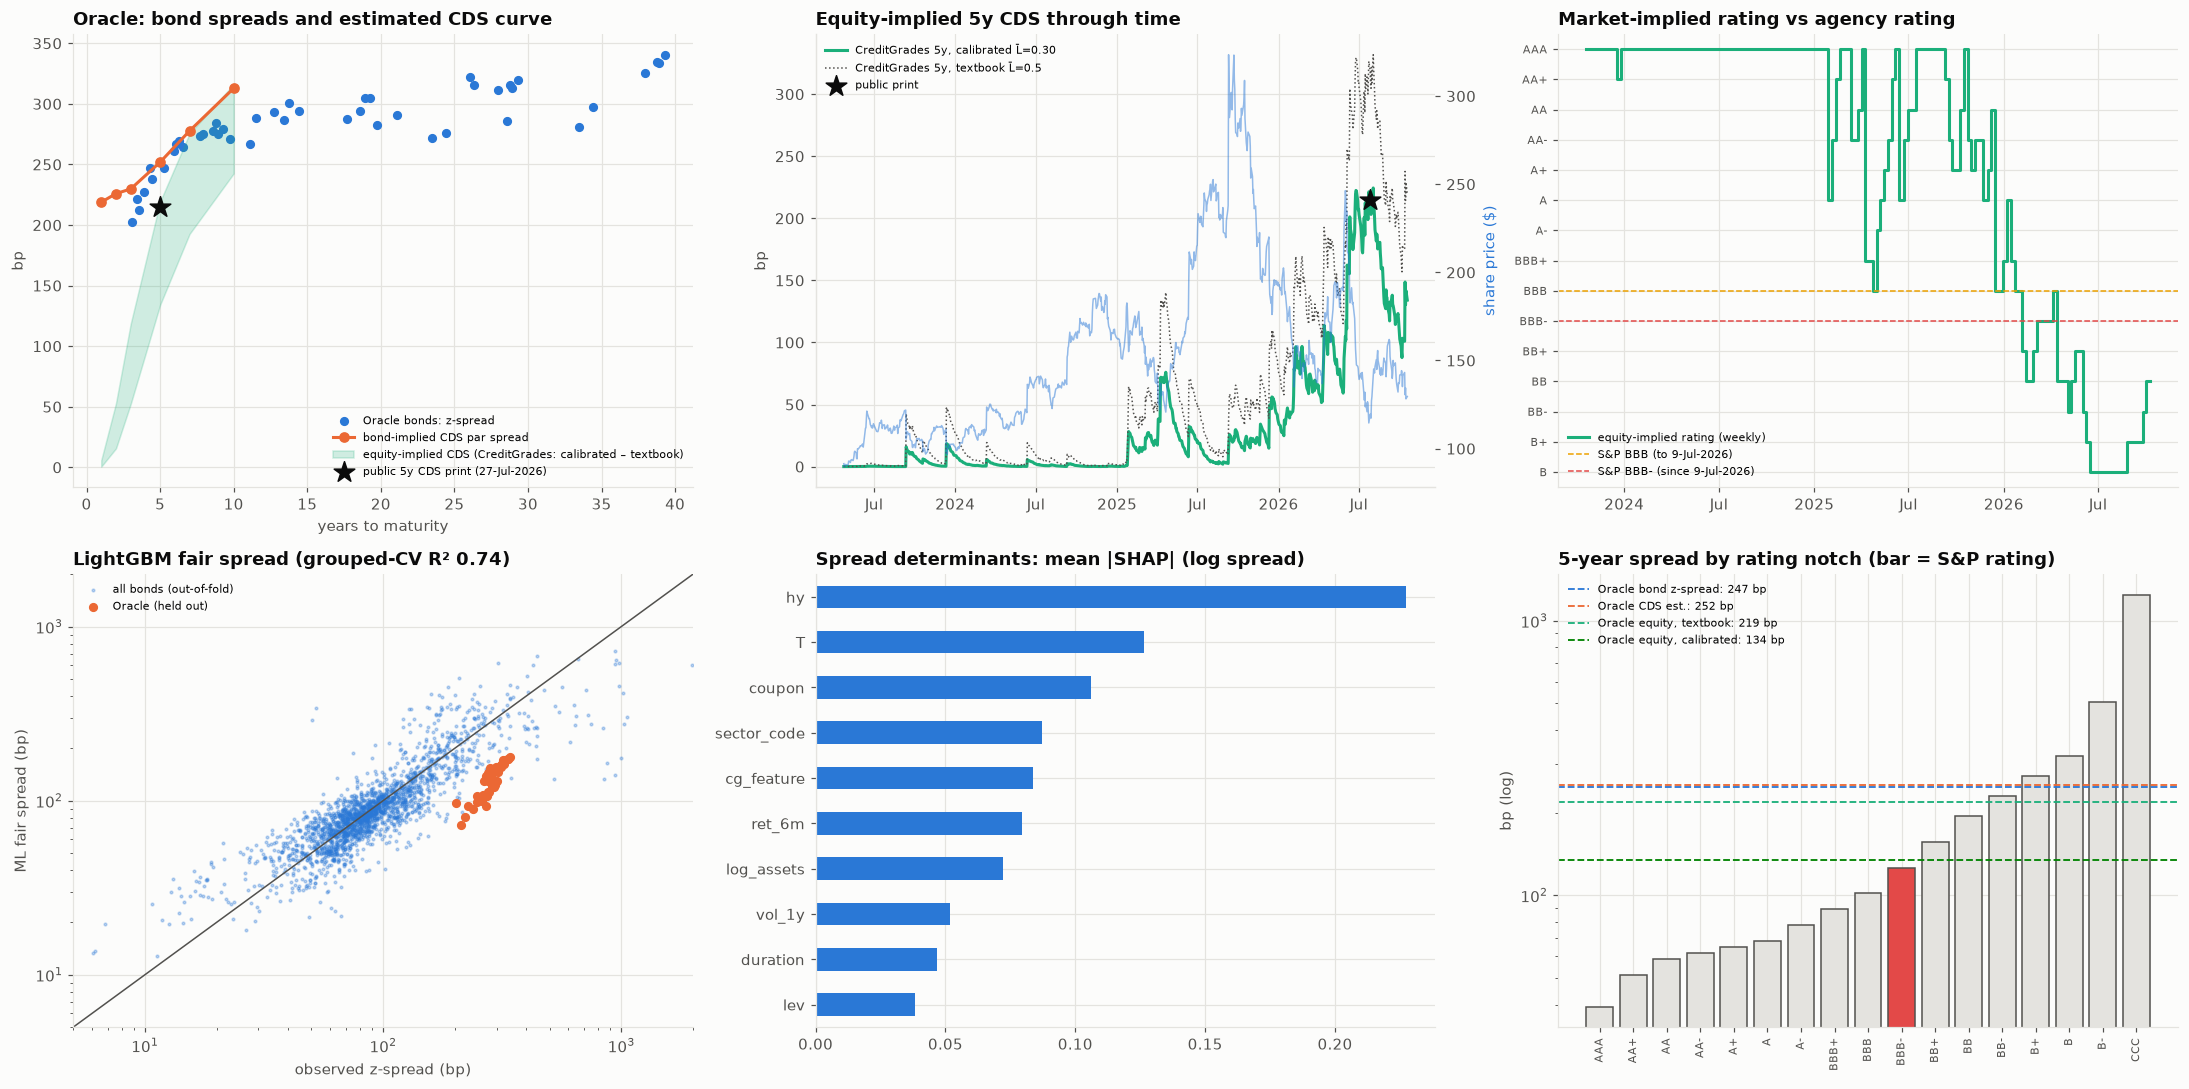

In [11]:
fig, axes = plt.subplots(2, 3, figsize=(20, 10))
ax = axes[0, 0]
ax.scatter(
    orcl["T"],
    orcl["z_bp"],
    color=PALETTE[0],
    s=25,
    label="Oracle bonds: z-spread",
)
tt = np.linspace(0.5, 40, 80)
ax.plot(
    CDS_TENORS,
    bond_cds.values,
    "o-",
    color=PALETTE[1],
    label="bond-implied CDS par spread",
)
ax.fill_between(
    CDS_TENORS,
    cg_term.values,
    cg_term_std.values,
    color=PALETTE[2],
    alpha=0.2,
    label="equity-implied CDS (CreditGrades: calibrated – textbook)",
)
ax.scatter(
    [5],
    [CDS_PRINT[1]],
    marker="*",
    s=200,
    color=INK,
    zorder=5,
    label="public 5y CDS print (27-Jul-2026)",
)
ax.set_xlabel("years to maturity")
ax.set_ylabel("bp")
ax.set_title("Oracle: bond spreads and estimated CDS curve")
ax.legend(fontsize=7)
ax = axes[0, 1]
ax.plot(
    daily.index,
    daily["cg_calibrated"],
    color=PALETTE[2],
    label=f"CreditGrades 5y, calibrated L̄={Lbar_cal:.2f}",
)
ax.plot(
    daily.index,
    daily["cg_standard"],
    color=INK_2,
    lw=1,
    ls=":",
    label="CreditGrades 5y, textbook L̄=0.5",
)
ax.scatter(
    [CDS_PRINT[0]],
    [CDS_PRINT[1]],
    marker="*",
    s=200,
    color=INK,
    zorder=5,
    label="public print",
)
ax2 = ax.twinx()
ax2.plot(daily.index, daily["S"], color=PALETTE[0], lw=1, alpha=0.5)
ax2.set_ylabel("share price ($)", color=PALETTE[0])
ax2.grid(False)
ax.set_title("Equity-implied 5y CDS through time")
ax.set_ylabel("bp")
ax.legend(fontsize=7, loc="upper left")
ax = axes[0, 2]
ax.plot(
    hist.index,
    hist["eir"],
    color=PALETTE[2],
    drawstyle="steps-post",
    label="equity-implied rating (weekly)",
)
ax.axhline(
    notch_no["BBB"],
    color=PALETTE[3],
    ls="--",
    lw=1,
    label="S&P BBB (to 9-Jul-2026)",
)
ax.axhline(
    notch_no["BBB-"],
    color=PALETTE[7],
    ls="--",
    lw=1,
    label="S&P BBB- (since 9-Jul-2026)",
)
ax.set_yticks(range(len(NOTCHES)))
ax.set_yticklabels(NOTCHES, fontsize=7)
ax.invert_yaxis()
ax.set_ylim(
    min(hist["eir"].max(), notch_no["CCC"]) + 0.5,
    max(hist["eir"].min(), 0) - 0.5,
)
ax.set_title("Market-implied rating vs agency rating")
ax.legend(fontsize=7)
ax = axes[1, 0]
lim = (5, 2000)
p = np.exp(oof["lightgbm"])
ax.scatter(
    train["z_bp"],
    p,
    s=3,
    alpha=0.3,
    color=PALETTE[0],
    label="all bonds (out-of-fold)",
)
ax.scatter(
    orcl_ml["z_bp"],
    orcl_ml["ml_fair_bp"],
    s=25,
    color=PALETTE[1],
    label="Oracle (held out)",
)
ax.plot(lim, lim, color=INK_2, lw=1)
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlim(lim)
ax.set_ylim(lim)
ax.set_xlabel("observed z-spread (bp)")
ax.set_ylabel("ML fair spread (bp)")
ax.set_title(
    "LightGBM fair spread (grouped-CV R²"
    f" {score.loc['lightgbm', 'R² (log spread)']:.2f})"
)
ax.legend(fontsize=7)
ax = axes[1, 1]
shap_imp.iloc[::-1].plot.barh(ax=ax, color=PALETTE[0])
ax.set_title("Spread determinants: mean |SHAP| (log spread)")
ax = axes[1, 2]
b5 = notch_spreads(row_now, 5.0).pipe(np.exp)
ax.bar(
    range(len(NOTCHES)),
    b5.values,
    color=[PALETTE[7] if n == AGENCY_RATING else GRID for n in NOTCHES],
    edgecolor=INK_2,
)
ax.set_xticks(range(len(NOTCHES)))
ax.set_xticklabels(NOTCHES, rotation=90, fontsize=7)
ax.set_yscale("log")
for lab, v, c in [
    ("bond z-spread", z5, PALETTE[0]),
    ("CDS est.", CDS_EST, PALETTE[1]),
    ("equity, textbook", cg_term_std[5], PALETTE[2]),
    ("equity, calibrated", cg_term[5], PALETTE[5]),
]:
    ax.axhline(v, color=c, ls="--", lw=1.2, label=f"Oracle {lab}: {v:.0f} bp")
ax.set_title("5-year spread by rating notch (bar = S&P rating)")
ax.set_ylabel("bp (log)")
ax.legend(fontsize=7)
import matplotlib.dates as mdates

for a_ in (axes[0, 1], axes[0, 2]):
    loc_ = mdates.MonthLocator(bymonth=[1, 7])
    a_.xaxis.set_major_locator(loc_)
    a_.xaxis.set_major_formatter(mdates.ConciseDateFormatter(loc_))
plt.tight_layout()
save_fig(fig, "01_cds_triangulation_mir")
plt.show()

## 10. Reading the results and limitations

**The market prices Oracle as a BB credit.** On 19 October 2026, Oracle's 45 bonds trade at z-spreads over Treasuries from about 200 bp (2029) to 340 bp (2066), with **247 bp at five years**. That is three times the median of the investment-grade index (80 bp) and wider than the median high-yield bond in HYG (205 bp).

**Estimated CDS curve.**
- **Bond-implied (central estimate).** The hazard model reprices the bonds with a 16 bp spread RMSE and gives a 5-year CDS of **252 bp** (219 bp at 1 year, 313 bp at 10 years), with an implied 81% five-year risk-neutral survival. With zero basis, CDS and 5-year z-spread nearly coincide (+5 bp).
- **Validation against the public print.** The only public print (215 bp on 27 July) sits 37 bp below the October bond-implied level. Part of that is a genuinely negative CDS–bond basis (Treasury vs SOFR discounting, bond funding and liquidity premia). Part is the three months between the two dates. **215–252 bp is the honest range for the bond route.**
- **Equity-implied (CreditGrades).** With textbook parameters it gives **219 bp** today and 319 bp on the print date. Calibrating the recovery level to the print ($\bar L = 0.30$) gives **134 bp** today.
  - The structural route agrees on the level only when it is not anchored to a stressed day, which shows how sensitive the method is to its one free parameter.
  - It produces almost no spread at one year, the well-known short-end weakness of structural models: they cannot price jump-to-default.
  - Over three years it tracks the story well. Financial debt rose from $78bn to **$125bn** while equity volatility doubled to about 58%. The equity-implied 5-year spread climbed from about 30 bp in 2023 to above 300 bp at the June–July 2026 lows.

**The ML fair spread says Oracle trades about 150 bp wide of its fundamentals.**
- **Fit.** LightGBM explains log spreads across 2,139 bonds of 392 issuers with a grouped cross-validation R² of **0.74**, against 0.68 for the classic linear determinants regression. The median error is 13 bp vs 15 bp.
- **Drivers, in line with the literature.** The high-yield flag (a rating proxy) dominates, followed by maturity, coupon, sector, the structural spread, past equity returns, size and volatility. The linear coefficients have the textbook signs: +10 points of volatility widen spreads by about 12%, and higher leverage and poor 6-month returns widen them too.
- **Oracle.** Given its *observable* balance sheet (book leverage 0.41, very large assets, investment-grade index membership) and equity behaviour, peers trade at about **100 bp**. Oracle's 4–6-year bonds trade at about 247 bp.
- **Reading the gap.** The excess is a forward-looking premium for risks that trailing ratios do not show yet: the scale of committed AI capex, negative free cash flow and the announced funding needs. For an investor it is a "cheap" signal. For a risk officer it is a warning that the market expects the balance sheet to deteriorate.

**MIR gap: the market is three notches below S&P.** At five years, the rating bands from the ICE BofA indices are BBB 102 bp, BBB- 126 bp, BB+ 157 bp and BB 195 bp. Against S&P's BBB-:

| Implied rating | Spread | Gap |
|---|---|---|
| bond-implied | 247 bp → **BB-** | 3 notches |
| CDS-implied, zero basis | 252 bp → B+ | 4 notches |
| CDS-implied, July-print basis | 215 bp → BB- | 3 notches |
| equity-implied, textbook | 219 bp → **BB-** | 3 notches |
| equity-implied, calibrated | 134 bp → BBB- | 0 notches |

- **Lead time.** The weekly equity-implied rating fell below investment grade on **5 February 2026**, five months before S&P's downgrade from BBB to BBB- on 9 July. It bottomed at B in mid-June, a large and persistent negative gap that a credit officer would have escalated.

**Limitations**
- **No traded CDS.** Everything rests on bond prices, equity and one press-reported print. With a terminal, the CDS curve itself would replace route 1 and calibrate route 2.
- **The hazard model is simple.** Recovery is fixed at 40%, discounting is on Treasuries, and the bonds are treated as non-callable bullets. Make-whole calls and the deep-discount long bonds affect the long-end fit, where errors reach −40 bp.
- **CreditGrades is sensitive to its parameters.** Debt per share is book financial debt, updated quarterly with a 45-day lag, and operating leases and off-balance-sheet commitments (large for Oracle's data centres) are excluded. The model underprices low-leverage firms: equity-implied "AAA" in 2023–24 is a model artefact, not a market view.
- **The ML cross-section is a single snapshot.** Issuers are matched to tickers by name, which catches 58% of bonds and misses subsidiaries and private issuers. Leverage is book debt over assets, and "HY" is index membership, not the actual rating.
- **The MIR bands follow a stated assumption.** Every rating category is assumed to share the investment-grade maturity profile, and notches are interpolated. Moody's MIR uses issuer-level medians and its own bands.
- **The agency rating is S&P's**, as reported in July 2026. Moody's and Fitch were not verified here.

In [12]:
orcl.drop(columns=["isin"]).to_csv(
    OUT_DIR / "oracle_bond_spreads_and_fit.csv", index=False
)
tri.to_csv(OUT_DIR / "oracle_cds_term_structure.csv")
summary.to_csv(OUT_DIR / "oracle_cds_triangulation.csv", header=["value"])
implied.to_csv(OUT_DIR / "market_implied_ratings.csv")
hist[["S", "sigS", "D", "cg_standard", "cg_calibrated", "eir", "gap"]].assign(
    eir=lambda d: d["eir"].map(lambda i: NOTCHES[int(i)])
).to_csv(OUT_DIR / "equity_implied_cds_and_rating_history.csv")
score.to_csv(OUT_DIR / "spread_model_cv_scores.csv")
shap_imp.to_csv(
    OUT_DIR / "spread_determinants_shap.csv", header=["mean_abs_shap"]
)
print(
    "Outputs written:", ", ".join(sorted(p_.name for p_ in OUT_DIR.iterdir()))
)

Outputs written: 01_cds_triangulation_mir.png, equity_implied_cds_and_rating_history.csv, market_implied_ratings.csv, oracle_bond_spreads_and_fit.csv, oracle_cds_term_structure.csv, oracle_cds_triangulation.csv, spread_determinants_shap.csv, spread_model_cv_scores.csv


## References

### Finance and regulation

- Duffie, D., & Singleton, K. J. (1999). Modeling term structures of defaultable bonds. *The Review of Financial Studies, 12*(4), 687–720. https://doi.org/10.1093/rfs/12.4.687
- Collin-Dufresne, P., Goldstein, R. S., & Martin, J. S. (2001). The determinants of credit spread changes. *The Journal of Finance, 56*(6), 2177–2207. https://doi.org/10.1111/0022-1082.00402
- Longstaff, F. A., Mithal, S., & Neis, E. (2005). Corporate yield spreads: Default risk or liquidity? New evidence from the credit default swap market. *The Journal of Finance, 60*(5), 2213–2253. https://doi.org/10.1111/j.1540-6261.2005.00797.x
- Bai, J., & Collin-Dufresne, P. (2019). The CDS-bond basis. *Financial Management, 48*(2), 417–439. https://doi.org/10.1111/fima.12252
- Merton, R. C. (1974). On the pricing of corporate debt: The risk structure of interest rates. *The Journal of Finance, 29*(2), 449–470. https://doi.org/10.1111/j.1540-6261.1974.tb03058.x

### Machine learning and deep learning

- Ke, G., Meng, Q., Finley, T., Wang, T., Chen, W., Ma, W., Ye, Q., & Liu, T.-Y. (2017). LightGBM: A highly efficient gradient boosting decision tree. *Advances in Neural Information Processing Systems, 30*. https://proceedings.neurips.cc/paper/2017/hash/6449f44a102fde848669bdd9eb6b76fa-Abstract.html
- Lundberg, S. M., & Lee, S.-I. (2017). A unified approach to interpreting model predictions. *Advances in Neural Information Processing Systems, 30*. https://arxiv.org/abs/1705.07874
- Bianchi, D., Büchner, M., & Tamoni, A. (2021). Bond risk premiums with machine learning. *The Review of Financial Studies, 34*(2), 1046–1089. https://doi.org/10.1093/rfs/hhaa062